In [2]:
import os, zipfile
from google.colab import files

if not os.path.exists("carbon_intensity.csv"):
    uploaded = files.upload()                 # select data.zip in the popup
    for name in uploaded:
        if name.endswith(".zip"):
            zipfile.ZipFile(name).extractall(".")

print(sorted(f for f in os.listdir(".") if f.endswith(".csv")))

Saving carbon_intensity.csv to carbon_intensity.csv
Saving generation_mix.csv to generation_mix.csv
Saving weather.csv to weather.csv
['carbon_intensity.csv', 'generation_mix.csv', 'weather.csv']


In [3]:
import pandas as pd, numpy as np

# 1. Load
ci = pd.read_csv("carbon_intensity.csv", parse_dates=["from_utc"]).set_index("from_utc")
gm = pd.read_csv("generation_mix.csv", parse_dates=["from_utc"]).set_index("from_utc")
wx = pd.read_csv("weather.csv", parse_dates=["time_utc"]).set_index("time_utc")
wx.index = wx.index.tz_localize("UTC")   # weather file has no timezone, others do

# 2. Shape and date range
for name, d in [("carbon", ci), ("genmix", gm), ("weather", wx)]:
    print(name, d.shape, d.index.min(), "->", d.index.max())

# 3. Expected vs actual rows (carbon, every 30 min)
grid = pd.date_range(ci.index.min(), ci.index.max(), freq="30min", tz="UTC")
print("expected:", len(grid), "found:", len(ci), "missing:", len(grid) - len(ci))

# 4. Nulls
print(ci.isna().sum(), gm.isna().sum().sum(), wx.isna().sum().sum())

# 5. Where are the gaps?
a = ci["actual"].reindex(grid)
missing = a.isna()
run_id = (missing != missing.shift()).cumsum()
runs = missing.groupby(run_id).agg(["first", "size"])
runs = runs[runs["first"]]                       # keep only missing runs
runs["start"] = grid.to_series().groupby(run_id).first()[runs.index]
print(runs.sort_values("size", ascending=False).head())

# 6. Odd values
print(a.describe())
print("zeros:", (a == 0).sum())
for t in a[a == 0].index[:3]:
    print(t, a[t - pd.Timedelta("1h"): t + pd.Timedelta("1h")].tolist())

# 7. Is the vendor "forecast" really a forecast?
f = ci["forecast_neso"].reindex(grid)
for k in [0, 1, 2, 4, 24, 48]:
    print(k, round(f.corr(a.shift(k)), 4))

carbon (66407, 2) 2022-12-31 23:30:00+00:00 -> 2026-10-17 23:30:00+00:00
genmix (64912, 9) 2022-12-31 23:30:00+00:00 -> 2026-10-17 23:30:00+00:00
weather (33288, 8) 2023-01-01 00:00:00+00:00 -> 2026-10-18 23:00:00+00:00
expected: 66529 found: 66407 missing: 122
forecast_neso    43
actual            5
dtype: int64 0 0
        first  size                     start
actual                                       
4        True    91 2023-10-20 22:00:00+00:00
6        True    31 2024-06-11 23:00:00+00:00
2        True     5 2023-01-26 13:30:00+00:00
count    66402.000000
mean       132.546414
std         59.887512
min          0.000000
25%         80.000000
50%        127.000000
75%        178.000000
max        309.000000
Name: actual, dtype: float64
zeros: 6
2023-01-31 01:00:00+00:00 [103.0, 103.0, 0.0, 91.0, 89.0]
2023-06-07 09:30:00+00:00 [192.0, 124.0, 0.0, 0.0, 0.0]
2023-06-07 10:00:00+00:00 [124.0, 0.0, 0.0, 0.0, 0.0]
0 0.9733
1 0.9828
2 0.9845
4 0.9583
24 0.6284
48 0.5995


In [4]:
MAX_FILL = 6   # 6 x 30 min = 3 hours

# 1. Zeros are sensor glitches -> NaN
raw = ci["actual"].reindex(grid)
print("zeros turned into NaN:", (raw == 0).sum())
raw = raw.mask(raw == 0)

# 2. Master table
master = pd.DataFrame(index=grid)
master.index.name = "ts_utc"
master["actual_raw"] = raw                                    # label: real observations only
master["actual_filled"] = raw.interpolate(limit=MAX_FILL, limit_area="inside")   # features only
master["neso_forecast"] = ci["forecast_neso"].reindex(grid)   # benchmark only, never a feature

# 3. Generation mix (leave long gaps as NaN)
gmr = gm.reindex(grid).interpolate(limit=MAX_FILL, limit_area="inside")
for c in gmr.columns:
    master[f"mix_{c}"] = gmr[c]

# 4. Weather: hourly -> half-hourly
wxh = wx.reindex(grid.union(wx.index)).interpolate(limit=2).reindex(grid)
for c in wx.columns:
    master[f"wx_{c}"] = wxh[c]

# 5. Checks
print(master.shape)
print("actual_raw NaN:   ", master["actual_raw"].isna().sum())
print("actual_filled NaN:", master["actual_filled"].isna().sum())
print("genmix NaN:       ", master["mix_gas"].isna().sum())
print("weather NaN:      ", master["wx_central_temperature_2m"].isna().sum())

zeros turned into NaN: 6
(66529, 20)
actual_raw NaN:    133
actual_filled NaN: 110
genmix NaN:        1575
weather NaN:       1


In [5]:
MAX_FILL = 6   # 6 x 30 min = 3 hours

def fill_short_gaps(s, max_steps):
    """Interpolate a gap only if the WHOLE gap is <= max_steps long."""
    isna = s.isna()
    run_len = isna.groupby((isna != isna.shift()).cumsum()).transform("size")
    return s.interpolate(limit_area="inside").mask(isna & (run_len > max_steps))

raw = ci["actual"].reindex(grid)
print("zeros turned into NaN:", (raw == 0).sum())
raw = raw.mask(raw == 0)

master = pd.DataFrame(index=grid)
master.index.name = "ts_utc"
master["actual_raw"] = raw
master["actual_filled"] = fill_short_gaps(raw, MAX_FILL)
master["neso_forecast"] = ci["forecast_neso"].reindex(grid)

gmr = gm.reindex(grid).apply(lambda c: fill_short_gaps(c, MAX_FILL))
for c in gmr.columns:
    master[f"mix_{c}"] = gmr[c]

wxh = wx.reindex(grid.union(wx.index)).interpolate(limit=2).reindex(grid)
for c in wx.columns:
    master[f"wx_{c}"] = wxh[c]

print(master.shape)
print("actual_raw NaN:   ", master["actual_raw"].isna().sum())
print("actual_filled NaN:", master["actual_filled"].isna().sum())
print("genmix NaN:       ", master["mix_gas"].isna().sum())
print("weather NaN:      ", master["wx_central_temperature_2m"].isna().sum())

zeros turned into NaN: 6
(66529, 20)
actual_raw NaN:    133
actual_filled NaN: 122
genmix NaN:        1617
weather NaN:       1


In [6]:
H_MAX = 48
MIX = ["wind","gas","solar","imports","nuclear","biomass","coal","hydro"]

def build(master, origin_step=2):
    n = len(master)
    yf = master.actual_filled.to_numpy()
    yr = master.actual_raw.to_numpy()
    neso = master.neso_forecast.to_numpy()
    s = master.actual_filled
    r24   = s.rolling(48,  min_periods=40).mean().to_numpy()
    r24sd = s.rolling(48,  min_periods=40).std().to_numpy()
    r7    = s.rolling(336, min_periods=280).mean().to_numpy()

    loc = master.index.tz_convert("Europe/London")        # UK local clock, not UTC
    hod = (loc.hour + loc.minute/60).to_numpy()
    dow = loc.dayofweek.to_numpy()
    doy = loc.dayofyear.to_numpy()

    origins = np.arange(336, n-1, origin_step)             # need 7 days of history
    hs = np.arange(1, H_MAX+1)
    oi = np.repeat(origins, len(hs))                       # origin index
    hh = np.tile(hs, len(origins))                         # horizon
    tj = oi + hh                                           # target index
    k = tj < n
    oi, hh, tj = oi[k], hh[k], tj[k]

    d = {
        "origin_ts": master.index[oi], "target_ts": master.index[tj], "h": hh,
        "y": yr[tj], "neso_forecast": neso[tj],
        # known at the origin
        "y_now": yf[oi], "y_lag_1h": yf[oi-2], "y_lag_3h": yf[oi-6],
        "y_lag_6h": yf[oi-12], "y_lag_24h": yf[oi-48],
        "roll_mean_24h": r24[oi], "roll_std_24h": r24sd[oi], "roll_mean_7d": r7[oi],
        # same time yesterday / last week as the TARGET (both are <= origin, so legal)
        "y_target_minus_1d": yf[tj-48], "y_target_minus_7d": yf[tj-336],
        # calendar of the target time (known in advance)
        "hod": hod[tj], "dow": dow[tj], "is_weekend": (dow[tj] >= 5).astype(int),
        "doy_sin": np.sin(2*np.pi*doy[tj]/365.25), "doy_cos": np.cos(2*np.pi*doy[tj]/365.25),
    }
    for f in MIX:
        d[f"mix_{f}_now"] = master[f"mix_{f}"].to_numpy()[oi]
    out = pd.DataFrame(d)
    out["clim_key"] = (out.hod*2).astype(int)
    out["month"] = out.target_ts.dt.tz_convert("Europe/London").dt.month
    return out

FEATS_A = ["h","y_now","y_lag_1h","y_lag_3h","y_lag_6h","y_lag_24h",
           "roll_mean_24h","roll_std_24h","roll_mean_7d",
           "y_target_minus_1d","y_target_minus_7d",
           "hod","dow","is_weekend","doy_sin","doy_cos"] + [f"mix_{f}_now" for f in MIX]

df = build(master)
print(df.shape)
df.head()

(1588056, 30)


,origin_ts,target_ts,h,y,neso_forecast,y_now,y_lag_1h,y_lag_3h,y_lag_6h,y_lag_24h,...,mix_wind_now,mix_gas_now,mix_solar_now,mix_imports_now,mix_nuclear_now,mix_biomass_now,mix_coal_now,mix_hydro_now,clim_key,month
0,2023-01-07 23:30:00+00:00,2023-01-08 00:00:00+00:00,1,59.0,72.0,61.0,71.0,56.0,70.0,51.0,...,66.2,11.7,0.0,1.1,16.8,1.7,0.8,1.8,0,1
1,2023-01-07 23:30:00+00:00,2023-01-08 00:30:00+00:00,2,64.0,70.0,61.0,71.0,56.0,70.0,51.0,...,66.2,11.7,0.0,1.1,16.8,1.7,0.8,1.8,1,1
2,2023-01-07 23:30:00+00:00,2023-01-08 01:00:00+00:00,3,64.0,58.0,61.0,71.0,56.0,70.0,51.0,...,66.2,11.7,0.0,1.1,16.8,1.7,0.8,1.8,2,1
3,2023-01-07 23:30:00+00:00,2023-01-08 01:30:00+00:00,4,61.0,57.0,61.0,71.0,56.0,70.0,51.0,...,66.2,11.7,0.0,1.1,16.8,1.7,0.8,1.8,3,1
4,2023-01-07 23:30:00+00:00,2023-01-08 02:00:00+00:00,5,70.0,67.0,61.0,71.0,56.0,70.0,51.0,...,66.2,11.7,0.0,1.1,16.8,1.7,0.8,1.8,4,1


In [7]:
TRAIN_END  = pd.Timestamp("2024-06-30", tz="UTC")
CAL_START  = pd.Timestamp("2024-07-01", tz="UTC")
CAL_END    = pd.Timestamp("2025-06-30", tz="UTC")
TEST_START = pd.Timestamp("2025-07-01", tz="UTC")
PURGE = pd.Timedelta(hours=24)

o = df.origin_ts
tr = df[o < TRAIN_END - PURGE]
ca = df[(o >= CAL_START) & (o < CAL_END - PURGE)].dropna(subset=["y"]).copy()
te = df[o >= TEST_START].dropna(subset=["y"]).copy()
print(f"train={tr.y.notna().sum():,}  cal={len(ca):,}  test={len(te):,}")

# leakage checks: these must pass
assert tr.target_ts.max() < ca.origin_ts.min(), "train overlaps calibration"
assert ca.target_ts.max() < te.origin_ts.min(), "calibration overlaps test"
for _, r in df.sample(300, random_state=1).iterrows():
    i = master.index.get_loc(r.origin_ts); j = master.index.get_loc(r.target_ts)
    assert j-48 <= i and j-336 <= i and r.h == j-i, "feature looks into the future"
print("leakage checks passed")

train=616,656  cal=418,176  test=545,424
leakage checks passed


In [8]:
# Climatology: average by (month, half-hour of day), computed from TRAIN only
clim = tr.dropna(subset=["y"]).groupby(["month", "clim_key"]).y.mean()
te["clim"] = [clim.get((m, k), np.nan) for m, k in zip(te.month, te.clim_key)]

te["persistence"] = te["y_now"]              # tomorrow looks like right now
te["naive_1d"]    = te["y_target_minus_1d"]  # same half-hour yesterday
te["naive_7d"]    = te["y_target_minus_7d"]  # same half-hour last week

mae = lambda y, p: float(np.mean(np.abs(y - p)))
cols = ["persistence", "naive_1d", "naive_7d", "clim", "neso_forecast"]

# compare all methods on the SAME rows
common = te[cols + ["y"]].notna().all(axis=1)
print("usable rows:", common.sum(), "of", len(te))
for c in cols:
    print(f"{c:15s} MAE = {mae(te.y[common], te[c][common]):6.2f}")

# MAE by forecast horizon
HZ = [1, 2, 4, 8, 12, 24, 36, 48]            # half-hours -> 0.5h ... 24h
T = te[common]
rows = [{"horizon_h": h/2, **{c: round(mae(T.y[T.h == h], T[c][T.h == h]), 2) for c in cols}} for h in HZ]
pd.DataFrame(rows)

usable rows: 545016 of 545424
persistence     MAE =  38.27
naive_1d        MAE =  38.98
naive_7d        MAE =  52.90
clim            MAE =  46.66
neso_forecast   MAE =   9.73


,horizon_h,persistence,naive_1d,naive_7d,clim,neso_forecast
0,0.5,4.64,38.99,52.96,46.67,9.73
1,1.0,8.98,39.00,52.98,46.63,9.74
2,2.0,16.39,39.00,52.97,46.63,9.74
3,4.0,28.53,39.00,52.96,46.63,9.74
4,6.0,36.73,39.00,52.94,46.63,9.74
5,12.0,43.32,38.99,52.91,46.65,9.74
6,18.0,47.18,38.98,52.88,46.65,9.74
7,24.0,38.98,38.98,52.84,46.64,9.74


In [9]:
from sklearn.ensemble import HistGradientBoostingRegressor as HGB

QS = {"lo": 0.1, "med": 0.5, "hi": 0.9}
PARAMS = dict(learning_rate=0.1, max_leaf_nodes=31, min_samples_leaf=200,
              early_stopping=False, random_state=0)
MAX_ITER = 500
pin = lambda y, p, q: float(np.mean(np.maximum(q*(y-p), (q-1)*(y-p))))   # pinball loss

def pick_iter(tr, feats, q):
    """Choose #trees on the LAST 3 months of train, in time order."""
    cut = pd.Timestamp("2024-04-01", tz="UTC")
    a = tr[tr.origin_ts < cut - PURGE].dropna(subset=["y"])
    b = tr[tr.origin_ts >= cut].dropna(subset=["y"])
    m = HGB(loss="quantile", quantile=q, max_iter=MAX_ITER, **PARAMS).fit(a[feats], a.y)
    losses = [pin(b.y.to_numpy(), p, q) for p in m.staged_predict(b[feats])]
    return int(np.argmin(losses)) + 1

trv = tr.dropna(subset=["y"])
models = {}
for k, q in QS.items():
    it = pick_iter(tr, FEATS_A, q)
    models[k] = HGB(loss="quantile", quantile=q, max_iter=it, **PARAMS).fit(trv[FEATS_A], trv.y)
    print(f"q={q}: best trees = {it}", flush=True)

q=0.1: best trees = 15
q=0.5: best trees = 36
q=0.9: best trees = 497


In [10]:
te["A_med"] = models["med"].predict(te[FEATS_A])
T = te[common]
rows = [{"horizon_h": h/2,
         "best_baseline": round(min(mae(T.y[T.h == h], T[c][T.h == h])
                                    for c in ["persistence", "naive_1d", "clim"]), 2),
         "model_A": round(mae(T.y[T.h == h], T.A_med[T.h == h]), 2)} for h in HZ]
display(pd.DataFrame(rows))
print("overall model MAE:", round(mae(T.y, T.A_med), 2))

,horizon_h,best_baseline,model_A
0,0.5,4.64,10.50
1,1.0,8.98,11.90
2,2.0,16.39,15.29
3,4.0,28.53,21.80
4,6.0,36.73,26.55
5,12.0,38.99,33.80
6,18.0,38.98,37.24
7,24.0,38.98,37.84


overall model MAE: 30.85


In [12]:
tr, ca, te = tr.copy(), ca.copy(), te.copy()
for d in (tr, ca, te):
    d["dy"] = d["y"] - d["y_now"]            # change relative to right now

def pick_iter_dy(tr, feats, q):
    cut = pd.Timestamp("2024-04-01", tz="UTC")
    base = tr.dropna(subset=["dy"])
    a = base[base.origin_ts < cut - PURGE]
    b = base[base.origin_ts >= cut]
    m = HGB(loss="quantile", quantile=q, max_iter=MAX_ITER, **PARAMS).fit(a[feats], a.dy)
    losses = [pin(b.dy.to_numpy(), p, q) for p in m.staged_predict(b[feats])]
    return int(np.argmin(losses)) + 1

trd = tr.dropna(subset=["dy"])
models_dy = {}
for k, q in QS.items():
    it = pick_iter_dy(tr, FEATS_A, q)
    models_dy[k] = HGB(loss="quantile", quantile=q, max_iter=it, **PARAMS).fit(trd[FEATS_A], trd.dy)
    print(f"q={q}: best trees = {it}", flush=True)

te["A_dy_med"] = models_dy["med"].predict(te[FEATS_A]) + te["y_now"]
T = te[common]
rows = [{"horizon_h": h/2,
         "best_baseline": round(min(mae(T.y[T.h == h], T[c][T.h == h])
                                    for c in ["persistence", "naive_1d", "clim"]), 2),
         "A_direct": round(mae(T.y[T.h == h], T.A_med[T.h == h]), 2),
         "A_delta":  round(mae(T.y[T.h == h], T.A_dy_med[T.h == h]), 2)} for h in HZ]
display(pd.DataFrame(rows))
print("overall:", round(mae(T.y, T.A_med), 2), "(direct)  vs", round(mae(T.y, T.A_dy_med), 2), "(delta)")

q=0.1: best trees = 23
q=0.5: best trees = 26
q=0.9: best trees = 451


,horizon_h,best_baseline,A_direct,A_delta
0,0.5,4.64,10.50,7.96
1,1.0,8.98,11.90,9.65
2,2.0,16.39,15.29,13.52
3,4.0,28.53,21.80,20.82
4,6.0,36.73,26.55,26.05
5,12.0,38.99,33.80,33.88
6,18.0,38.98,37.24,38.67
7,24.0,38.98,37.84,37.47


overall: 30.85 (direct)  vs 30.92 (delta)


In [13]:
def try_params(params, target, q=0.5, max_iter=600):
    cut = pd.Timestamp("2024-04-01", tz="UTC")
    base = tr.dropna(subset=[target, "y_now"])
    a = base[base.origin_ts < cut - PURGE]
    b = base[base.origin_ts >= cut]
    m = HGB(loss="quantile", quantile=q, max_iter=max_iter, early_stopping=False,
            random_state=0, **params).fit(a[FEATS_A], a[target])
    losses = [pin(b[target].to_numpy(), p, q) for p in m.staged_predict(b[FEATS_A])]
    return int(np.argmin(losses)) + 1, 2 * min(losses)      # 2*pinball(q=.5) = MAE

configs = {
  "base (leaf 200)":       dict(learning_rate=0.1,  max_leaf_nodes=31, min_samples_leaf=200),
  "leaf 2000":             dict(learning_rate=0.05, max_leaf_nodes=15, min_samples_leaf=2000),
  "leaf 5000 + l2":        dict(learning_rate=0.05, max_leaf_nodes=15, min_samples_leaf=5000, l2_regularization=10),
  "small trees, slow":     dict(learning_rate=0.03, max_leaf_nodes=8,  min_samples_leaf=5000, l2_regularization=10),
}
rows = []
for name, p in configs.items():
    for target in ["y", "dy"]:
        best, val_mae = try_params(p, target)
        rows.append({"config": name, "target": target, "best_trees": best, "val_MAE": round(val_mae, 2)})
        print(rows[-1], flush=True)
pd.DataFrame(rows)

{'config': 'base (leaf 200)', 'target': 'y', 'best_trees': 35, 'val_MAE': 31.6}
{'config': 'base (leaf 200)', 'target': 'dy', 'best_trees': 26, 'val_MAE': 26.33}
{'config': 'leaf 2000', 'target': 'y', 'best_trees': 86, 'val_MAE': 29.89}
{'config': 'leaf 2000', 'target': 'dy', 'best_trees': 64, 'val_MAE': 26.34}
{'config': 'leaf 5000 + l2', 'target': 'y', 'best_trees': 99, 'val_MAE': 29.87}
{'config': 'leaf 5000 + l2', 'target': 'dy', 'best_trees': 53, 'val_MAE': 26.3}
{'config': 'small trees, slow', 'target': 'y', 'best_trees': 198, 'val_MAE': 29.05}
{'config': 'small trees, slow', 'target': 'dy', 'best_trees': 116, 'val_MAE': 26.27}


,config,target,best_trees,val_MAE
0,base (leaf 200),y,35,31.60
1,base (leaf 200),dy,26,26.33
2,leaf 2000,y,86,29.89
3,leaf 2000,dy,64,26.34
4,leaf 5000 + l2,y,99,29.87
5,leaf 5000 + l2,dy,53,26.30
6,"small trees, slow",y,198,29.05
7,"small trees, slow",dy,116,26.27


In [14]:
BEST = dict(learning_rate=0.03, max_leaf_nodes=8, min_samples_leaf=5000, l2_regularization=10)

cut = pd.Timestamp("2024-04-01", tz="UTC")
base = tr.dropna(subset=["dy", "y_now"])
a = base[base.origin_ts < cut - PURGE]
b = base[base.origin_ts >= cut].copy()

m_y  = HGB(loss="quantile", quantile=0.5, max_iter=198, early_stopping=False,
           random_state=0, **BEST).fit(a[FEATS_A], a.y)
m_dy = HGB(loss="quantile", quantile=0.5, max_iter=116, early_stopping=False,
           random_state=0, **BEST).fit(a[FEATS_A], a.dy)

b["p_y"]  = m_y.predict(b[FEATS_A])
b["p_dy"] = m_dy.predict(b[FEATS_A]) + b["y_now"]

tab = b.groupby("h").apply(lambda g: pd.Series({"direct": mae(g.y, g.p_y),
                                                "delta":  mae(g.y, g.p_dy)}))
tab["delta_better"] = tab["delta"] < tab["direct"]
print(tab.loc[[1, 2, 4, 8, 12, 16, 24, 36, 48]].round(2))
print("delta better for h =", [int(h) for h in tab.index[tab.delta_better]])

    direct  delta  delta_better
h                              
1    16.25   7.76          True
2    16.92   9.32          True
4    18.29  12.17          True
8    21.50  17.54          True
12   25.85  21.80          True
16   27.48  23.88          True
24   30.40  26.93          True
36   33.99  33.69          True
48   35.48  34.67          True
delta better for h = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48]


/tmp/ipykernel_2599/1250445208.py:16: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  tab = b.groupby("h").apply(lambda g: pd.Series({"direct": mae(g.y, g.p_y),


q=0.1: best trees = 190
q=0.5: best trees = 116
q=0.9: best trees = 381


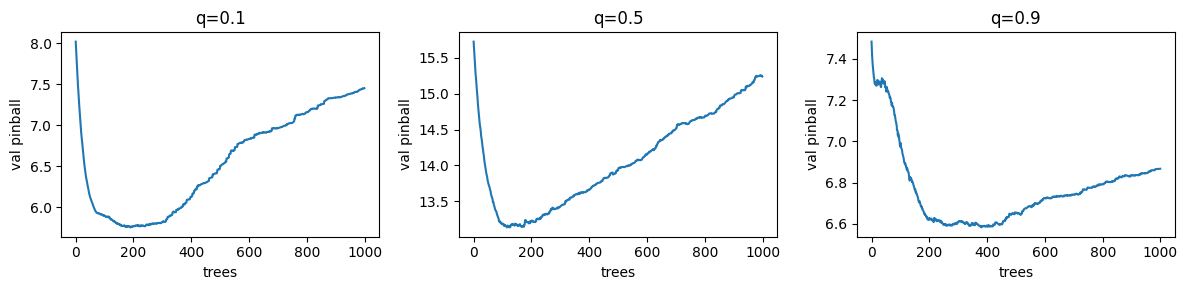

,horizon_h,best_baseline,final_model
0,0.5,4.64,8.86
1,1.0,8.98,10.54
2,2.0,16.39,14.44
3,4.0,28.53,21.96
4,6.0,36.73,27.45
5,12.0,38.99,34.81
6,18.0,38.98,39.51
7,24.0,38.98,37.26


overall MAE: 31.75
RAW 10-90% interval coverage on test: 75.7%  (target: 80%)


In [15]:
import matplotlib.pyplot as plt

MAXIT = 1000
base = tr.dropna(subset=["dy", "y_now"])
a = base[base.origin_ts < cut - PURGE]
b = base[base.origin_ts >= cut]

def best_trees(q):
    m = HGB(loss="quantile", quantile=q, max_iter=MAXIT, early_stopping=False,
            random_state=0, **BEST).fit(a[FEATS_A], a.dy)
    losses = [pin(b.dy.to_numpy(), p, q) for p in m.staged_predict(b[FEATS_A])]
    return int(np.argmin(losses)) + 1, losses

trd = tr.dropna(subset=["dy"])
models_final, curves = {}, {}
for k, q in QS.items():
    it, losses = best_trees(q)
    curves[k] = losses
    print(f"q={q}: best trees = {it}" + ("   <-- hit the cap, consider raising MAXIT" if it >= MAXIT - 5 else ""), flush=True)
    models_final[k] = HGB(loss="quantile", quantile=q, max_iter=it, early_stopping=False,
                          random_state=0, **BEST).fit(trd[FEATS_A], trd.dy)

# validation loss curves
fig, ax = plt.subplots(1, 3, figsize=(12, 3))
for axi, (k, l) in zip(ax, curves.items()):
    axi.plot(l); axi.set_title(f"q={QS[k]}"); axi.set_xlabel("trees"); axi.set_ylabel("val pinball")
plt.tight_layout(); plt.show()

# raw quantile forecasts for calibration and test (add y_now back)
for d in (ca, te):
    for k in QS:
        d[f"F_{k}"] = models_final[k].predict(d[FEATS_A]) + d["y_now"]
    d["F_lo"] = np.minimum(d["F_lo"], d["F_med"])      # repair quantile crossing
    d["F_hi"] = np.maximum(d["F_hi"], d["F_med"])

# diagnostics on TEST (reporting only; no more tuning after this)
T = te[common]
rows = [{"horizon_h": h/2,
         "best_baseline": round(min(mae(T.y[T.h == h], T[c][T.h == h])
                                    for c in ["persistence", "naive_1d", "clim"]), 2),
         "final_model": round(mae(T.y[T.h == h], T.F_med[T.h == h]), 2)} for h in HZ]
display(pd.DataFrame(rows))
print("overall MAE:", round(mae(T.y, T.F_med), 2))
inside = ((T.y >= T.F_lo) & (T.y <= T.F_hi)).mean()
print(f"RAW 10-90% interval coverage on test: {100*inside:.1f}%  (target: 80%)")

In [16]:
import math

ALPHA = 0.2
BUCKETS = [(1, 4), (5, 12), (13, 24), (25, 36), (37, 48)]       # half-hours
bucket = lambda h: next(i for i, (a, b) in enumerate(BUCKETS) if a <= h <= b)

def offset(s, alpha=ALPHA):
    n = len(s); k = min(n, math.ceil((n + 1) * (1 - alpha)))
    return float(np.sort(s)[k - 1])

# conformity score = how far the true value falls OUTSIDE the raw interval (negative if inside)
cal = ca.dropna(subset=["F_lo", "F_hi", "y"]).copy()
cal["score"] = np.maximum(cal.F_lo - cal.y, cal.y - cal.F_hi)
q_glob = offset(cal.score.to_numpy())
cal["b"] = cal.h.map(bucket)
q_b = {b: offset(g.score.to_numpy()) for b, g in cal.groupby("b")}
print("global widening (gCO2/kWh):", round(q_glob, 2))
print("per-horizon widening:", {f"{a/2:g}-{b/2:g}h": round(q_b[i], 1) for i, (a, b) in enumerate(BUCKETS)})

te["C_lo"], te["C_hi"] = te.F_lo - q_glob, te.F_hi + q_glob                 # global
off = te.h.map(bucket).map(q_b)
te["H_lo"], te["H_hi"] = te.F_lo - off, te.F_hi + off                       # per horizon

T = te.dropna(subset=["F_lo", "F_hi", "y"]).copy()
methods = {"raw": ("F_lo", "F_hi"), "CQR global": ("C_lo", "C_hi"), "CQR per horizon": ("H_lo", "H_hi")}
print("\nOverall test coverage % and mean width:")
for name, (lo, hi) in methods.items():
    ins = ((T.y >= T[lo]) & (T.y <= T[hi])).mean() * 100
    print(f"  {name:16s} coverage={ins:5.1f}%   width={(T[hi] - T[lo]).mean():6.1f}")

T["b"] = T.h.map(bucket)
by_h = pd.DataFrame({n: ((T.y >= T[lo]) & (T.y <= T[hi])).groupby(T.b).mean() * 100
                     for n, (lo, hi) in methods.items()}).round(1)
by_h.index = [f"{a/2:g}-{b/2:g}h" for a, b in BUCKETS]
by_m = pd.DataFrame({n: ((T.y >= T[lo]) & (T.y <= T[hi])).groupby(T.month).mean() * 100
                     for n, (lo, hi) in methods.items()}).round(1)
print("\nCoverage % by horizon:"); display(by_h)
print("Coverage % by month:");   display(by_m)

global widening (gCO2/kWh): 3.41
per-horizon widening: {'0.5-2h': -0.9, '2.5-6h': 1.7, '6.5-12h': 3.5, '12.5-18h': 5.3, '18.5-24h': 6.1}

Overall test coverage % and mean width:
  raw              coverage= 75.7%   width=  92.7
  CQR global       coverage= 80.1%   width=  99.6
  CQR per horizon  coverage= 80.0%   width= 100.6

Coverage % by horizon:


,raw,CQR global,CQR per horizon
0.5-2h,83.3,90.5,80.5
2.5-6h,77.8,83.0,80.5
6.5-12h,74.9,79.4,79.4
12.5-18h,74.0,77.7,79.6
18.5-24h,74.4,78.0,80.5


Coverage % by month:


,raw,CQR global,CQR per horizon
month,,,
1,71.4,75.8,75.8
2,78.1,81.1,81.0
3,72.2,76.7,76.3
4,71.1,76.8,76.6
5,76.7,80.9,80.3
6,69.5,75.3,75.0
7,75.9,80.2,80.1
8,77.0,81.5,81.4
9,78.4,83.0,82.8


In [17]:
T["ym"] = T.target_ts.dt.tz_convert("Europe/London").dt.strftime("%Y-%m")
ym = ((T.y >= T.H_lo) & (T.y <= T.H_hi)).groupby(T.ym).mean().mul(100).round(1)
print(ym.to_string())

ym
2025-07    84.4
2025-08    86.3
2025-09    86.5
2025-10    83.4
2025-11    81.0
2025-12    80.5
2026-01    75.8
2026-02    81.0
2026-03    76.3
2026-04    76.6
2026-05    80.3
2026-06    75.0
2026-07    75.9
2026-08    76.5
2026-09    79.2
2026-10    83.1


In [18]:
W = 26                                                   # 13h = 26 half-hours
loc = te.origin_ts.dt.tz_convert("Europe/London")
s = te[(te.h <= W) & (loc.dt.hour == 18) & (loc.dt.minute == 30)]   # origins fall on :30

Y = s.pivot(index="origin_ts", columns="h", values="y")
P = s.pivot(index="origin_ts", columns="h", values="F_med")
N = s.pivot(index="origin_ts", columns="h", values="naive_1d")
assert Y.shape[1] == W
good = Y.notna().all(axis=1) & P.notna().all(axis=1) & N.notna().all(axis=1)
Y, P, N = Y[good].to_numpy(), P[good].to_numpy(), N[good].to_numpy()
print("evaluation days:", len(Y))

def block_means(M, L):                                   # mean over every possible L-slot block
    cs = np.concatenate([np.zeros((len(M), 1)), np.cumsum(M, axis=1)], axis=1)
    return (cs[:, L:] - cs[:, :-L]) / L

def run(D, n_boot=2000, seed=0):
    L = 2 * D
    real, predP, predN = block_means(Y, L), block_means(P, L), block_means(N, L)
    r = np.arange(len(real))
    imm = real[:, 0]
    mdl = real[r, predP.argmin(1)]
    nav = real[r, predN.argmin(1)]
    orc = real.min(1)
    rnd = real.mean(1)
    idx = np.random.default_rng(seed).integers(0, len(real), (n_boot, len(real)))
    sav = 100 * (1 - mdl[idx].mean(1) / imm[idx].mean(1))
    return {"hours": D, "immediate": round(imm.mean(), 1), "random": round(rnd.mean(), 1),
            "naive_fc": round(nav.mean(), 1), "model_fc": round(mdl.mean(), 1), "oracle": round(orc.mean(), 1),
            "model_saving_%": round(100 * (1 - mdl.mean() / imm.mean()), 1),
            "95%CI": [round(float(np.percentile(sav, 2.5)), 1), round(float(np.percentile(sav, 97.5)), 1)],
            "naive_saving_%": round(100 * (1 - nav.mean() / imm.mean()), 1),
            "share_of_oracle_%": round(100 * (imm.mean() - mdl.mean()) / (imm.mean() - orc.mean()), 1)}

display(pd.DataFrame([run(D) for D in [2, 4, 6]]))

evaluation days: 473


,hours,immediate,random,naive_fc,model_fc,oracle,model_saving_%,95%CI,naive_saving_%,share_of_oracle_%
0,2,151.2,125.7,118.3,113.8,105.4,24.7,"[22.9, 26.5]",21.7,81.5
1,4,143.4,123.1,118.9,114.1,108.8,20.4,"[18.9, 21.9]",17.1,84.7
2,6,135.3,121.9,119.0,115.2,111.3,14.8,"[13.6, 16.0]",12.0,83.5


In [19]:
def paired_diff(D, n_boot=2000, seed=0):
    L = 2 * D
    real, predP, predN = block_means(Y, L), block_means(P, L), block_means(N, L)
    r = np.arange(len(real))
    mdl = real[r, predP.argmin(1)]
    nav = real[r, predN.argmin(1)]
    d = nav - mdl                                   # positive = model picks a cleaner block
    nb = len(d) // 7
    db = d[:nb * 7].reshape(nb, 7).mean(1)          # weekly blocks
    boots = db[np.random.default_rng(seed).integers(0, nb, (n_boot, nb))].mean(1)
    return round(float(d.mean()), 2), [round(float(np.percentile(boots, 2.5)), 2),
                                        round(float(np.percentile(boots, 97.5)), 2)]

for D in [2, 4, 6]:
    print(D, "h: naive - model (gCO2/kWh):", paired_diff(D))

2 h: naive - model (gCO2/kWh): (4.49, [2.34, 6.51])
4 h: naive - model (gCO2/kWh): (4.81, [3.26, 6.36])
6 h: naive - model (gCO2/kWh): (3.75, [2.65, 4.93])


In [20]:
T["ym"] = T.target_ts.dt.tz_convert("Europe/London").dt.strftime("%Y-%m")
ym = ((T.y >= T.H_lo) & (T.y <= T.H_hi)).groupby(T.ym).mean().mul(100).round(1)
print(ym.to_string())

ym
2025-07    84.4
2025-08    86.3
2025-09    86.5
2025-10    83.4
2025-11    81.0
2025-12    80.5
2026-01    75.8
2026-02    81.0
2026-03    76.3
2026-04    76.6
2026-05    80.3
2026-06    75.0
2026-07    75.9
2026-08    76.5
2026-09    79.2
2026-10    83.1


In [21]:
smp = T.sample(40000, random_state=0)
base_mae = mae(smp.y, models_final["med"].predict(smp[FEATS_A]) + smp.y_now)
rng = np.random.default_rng(0)
imp = {}
for f in FEATS_A:
    s2 = smp.copy()
    s2[f] = rng.permutation(s2[f].to_numpy())              # break this one feature
    imp[f] = mae(smp.y, models_final["med"].predict(s2[FEATS_A]) + smp.y_now) - base_mae
imp = pd.Series(imp).sort_values(ascending=False)
print(imp.head(10).round(2))

hod                  2.78
mix_solar_now        2.06
y_lag_1h             1.23
mix_gas_now          0.83
doy_cos              0.77
y_lag_24h            0.48
y_target_minus_7d    0.45
y_target_minus_1d    0.39
h                    0.37
mix_hydro_now        0.19
dtype: float64


In [22]:
import joblib, json
os.makedirs("deploy", exist_ok=True)
for k, m in models_final.items():
    joblib.dump(m, f"deploy/model_{k}.joblib")
meta = {"features": FEATS_A,
        "target": "dy = y - y_now (add y_now back)",
        "buckets_half_hours": BUCKETS,
        "cqr_offset_by_bucket": {str(i): v for i, v in q_b.items()},
        "alpha": ALPHA,
        "trained_on": "2023-01 to 2024-06"}
json.dump(meta, open("deploy/meta.json", "w"), indent=2)
print(os.listdir("deploy"))

['model_lo.joblib', 'model_med.joblib', 'model_hi.joblib', 'meta.json']


In [23]:
def make_features(hist, origin):
    """hist: cleaned table like `master` (30-min UTC index, actual_filled, mix_*), covering >= 7 days up to `origin`."""
    idx = pd.date_range(end=origin, periods=337, freq="30min")        # 336 steps back + origin
    s = hist["actual_filled"].reindex(idx)
    now = hist.loc[origin]
    w24, w7 = s.iloc[-48:], s.iloc[-336:]
    base = {
        "y_now": s.iloc[-1], "y_lag_1h": s.iloc[-3], "y_lag_3h": s.iloc[-7],
        "y_lag_6h": s.iloc[-13], "y_lag_24h": s.iloc[-49],
        "roll_mean_24h": w24.mean() if w24.notna().sum() >= 40 else np.nan,
        "roll_std_24h":  w24.std()  if w24.notna().sum() >= 40 else np.nan,
        "roll_mean_7d":  w7.mean()  if w7.notna().sum()  >= 280 else np.nan,
    }
    for f in MIX:
        base[f"mix_{f}_now"] = now[f"mix_{f}"]
    rows = []
    for h in range(1, 49):
        t = origin + pd.Timedelta(minutes=30 * h)
        lt = t.tz_convert("Europe/London")
        r = dict(base, h=h, target_ts=t,
                 y_target_minus_1d=s.iloc[288 + h],                   # same time yesterday (<= origin)
                 y_target_minus_7d=s.iloc[h],                         # same time last week
                 hod=lt.hour + lt.minute / 60, dow=lt.dayofweek, is_weekend=int(lt.dayofweek >= 5),
                 doy_sin=np.sin(2 * np.pi * lt.dayofyear / 365.25),
                 doy_cos=np.cos(2 * np.pi * lt.dayofyear / 365.25))
        rows.append(r)
    return pd.DataFrame(rows)

def predict(hist, origin, models, offsets):
    """Returns median forecast + calibrated 80% interval for the next 24h."""
    X = make_features(hist, origin)
    if pd.isna(X.y_now.iloc[0]):
        raise ValueError("no recent actual intensity at the origin: cannot forecast")
    out = X[["target_ts", "h"]].copy()
    for k in ("lo", "med", "hi"):
        out[k] = models[k].predict(X[FEATS_A]) + X["y_now"]
    out["lo"], out["hi"] = np.minimum(out.lo, out.med), np.maximum(out.hi, out.med)
    off = out.h.map(bucket).map(offsets)
    out["lo_cqr"], out["hi_cqr"] = out.lo - off, out.hi + off
    return out

In [24]:
# 1) live features == training features?
origins = pd.Series(df.origin_ts.unique()).sample(30, random_state=0)
worst = 0
for o in origins:
    ref = df[df.origin_ts == o].sort_values("h")
    X = make_features(master, o)
    for f in FEATS_A:
        a, b = ref[f].to_numpy(float), X[f].to_numpy(float)
        assert np.allclose(a, b, equal_nan=True), f"MISMATCH in {f} at {o}"
        worst = max(worst, np.nanmax(np.abs(a - b)) if np.isfinite(a).any() else 0)
print("features match on 30 random origins, worst abs diff:", worst)

# 2) live predictions == the test predictions we already scored?
for o in te.origin_ts.drop_duplicates().sample(5, random_state=1):
    p = predict(master, o, models_final, q_b)
    ref = te[te.origin_ts == o].sort_values("h")
    ok = ref.F_med.notna().to_numpy()
    assert np.allclose(p.med.to_numpy()[ok], ref.F_med.to_numpy()[ok]), f"prediction mismatch at {o}"
print("predictions match the evaluated test predictions")
print(predict(master, te.origin_ts.iloc[0], models_final, q_b).head())

features match on 30 random origins, worst abs diff: 5.95790083934844e-12
predictions match the evaluated test predictions
                  target_ts  h          lo         med          hi  \
0 2025-07-01 01:00:00+00:00  1  151.575263  170.152651  170.152651   
1 2025-07-01 01:30:00+00:00  2  151.275861  170.152651  170.152651   
2 2025-07-01 02:00:00+00:00  3  147.947714  170.579884  170.579884   
3 2025-07-01 02:30:00+00:00  4  144.120648  172.223800  172.223800   
4 2025-07-01 03:00:00+00:00  5  141.985546  172.086728  172.086728   

       lo_cqr      hi_cqr  
0  152.487441  169.240473  
1  152.188039  169.240473  
2  148.859892  169.667706  
3  145.032826  171.311622  
4  140.266744  173.805530  


In [25]:
Tt = te.dropna(subset=["F_lo", "F_med", "F_hi"]).copy()
Tt["b"] = Tt.h.map(bucket)
lab = [f"{a/2:g}-{b/2:g}h" for a, b in BUCKETS]

print("raw q90 below median (got clipped), % of rows, by horizon:")
print(((Tt.F_hi == Tt.F_med).groupby(Tt.b).mean() * 100).round(1).set_axis(lab).to_string())
print("\ncalibrated upper bound BELOW median, %:", ((Tt.H_hi < Tt.F_med).groupby(Tt.b).mean() * 100).round(1).tolist())
print("calibrated lower bound ABOVE median, %:", ((Tt.H_lo > Tt.F_med).groupby(Tt.b).mean() * 100).round(1).tolist())

raw q90 below median (got clipped), % of rows, by horizon:
0.5-2h      4.2
2.5-6h      0.1
6.5-12h     0.1
12.5-18h    0.0
18.5-24h    0.0

calibrated upper bound BELOW median, %: [5.1, 0.0, 0.0, 0.0, 0.0]
calibrated lower bound ABOVE median, %: [0.5, 0.0, 0.0, 0.0, 0.0]


In [26]:
te["H_lo"] = np.minimum(te.H_lo, te.F_med)
te["H_hi"] = np.maximum(te.H_hi, te.F_med)

T = te.dropna(subset=["F_lo", "F_hi", "y"])
ins = ((T.y >= T.H_lo) & (T.y <= T.H_hi)).mean() * 100
print(f"CQR per horizon after median-clip: coverage={ins:.1f}%  width={(T.H_hi - T.H_lo).mean():.1f}")

CQR per horizon after median-clip: coverage=80.0%  width=100.6


latest usable observation: 2026-10-20 07:00:00+00:00 | rows of history: 385


,target_ts,h,lo,med,hi,lo_cqr,hi_cqr
0,2026-10-20 07:30:00+00:00,1,117.765230,140.518329,166.452481,118.677408,165.540303
1,2026-10-20 08:00:00+00:00,2,116.773818,140.518329,162.488046,117.685996,161.575868
2,2026-10-20 08:30:00+00:00,3,111.139785,139.428163,169.394355,112.051963,168.482177
3,2026-10-20 09:00:00+00:00,4,105.639731,138.280940,168.642169,106.551908,167.729991
4,2026-10-20 09:30:00+00:00,5,98.395036,136.982268,172.025190,96.676234,173.743992


Best 3h charging window: Tue 11:30 -> 14:30 UTC, forecast avg 133 gCO2/kWh


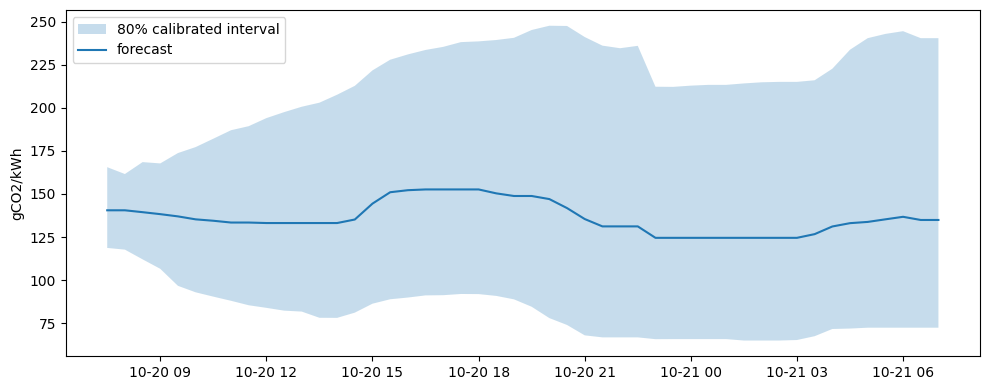

In [27]:
import requests
BASE = "https://api.carbonintensity.org.uk"

def fetch_recent(days=8):
    end = pd.Timestamp.now(tz="UTC").floor("30min")
    start = end - pd.Timedelta(days=days)
    f = lambda t: t.strftime("%Y-%m-%dT%H:%MZ")
    ci_ = requests.get(f"{BASE}/intensity/{f(start)}/{f(end)}", timeout=60).json()["data"]
    gm_ = requests.get(f"{BASE}/generation/{f(start)}/{f(end)}", timeout=60).json()["data"]
    act = pd.Series({pd.Timestamp(x["from"]): x["intensity"]["actual"] for x in ci_}, dtype=float).sort_index()
    mix = pd.DataFrame({pd.Timestamp(x["from"]): {m["fuel"]: m["perc"] for m in x["generationmix"]}
                        for x in gm_}).T.sort_index()
    return act, mix

def build_hist(act, mix):
    grid = pd.date_range(act.index.min(), act.index.max(), freq="30min")
    raw = act.reindex(grid)
    raw = raw.mask(raw == 0)                                   # same glitch rule as training
    hist = pd.DataFrame(index=grid)
    hist["actual_filled"] = fill_short_gaps(raw, MAX_FILL)     # same gap rule as training
    m = mix.reindex(grid).apply(lambda c: fill_short_gaps(c, MAX_FILL))
    for f in MIX:
        hist[f"mix_{f}"] = m[f]
    return hist

def best_window(fc, hours, window_slots=26):
    """Cheapest contiguous block (by median forecast) inside the next `window_slots` half-hours."""
    L = 2 * hours
    m = fc.med.iloc[:window_slots].to_numpy()
    cs = np.r_[0, np.cumsum(m)]
    means = (cs[L:] - cs[:-L]) / L
    s = int(means.argmin())
    return fc.target_ts.iloc[s], fc.target_ts.iloc[s + L - 1] + pd.Timedelta(minutes=30), float(means[s])

# load saved artifacts (this is what the web app will do)
models = {k: joblib.load(f"deploy/model_{k}.joblib") for k in ("lo", "med", "hi")}
meta = json.load(open("deploy/meta.json"))
offsets = {int(k): v for k, v in meta["cqr_offset_by_bucket"].items()}

act, mix = fetch_recent()
hist = build_hist(act, mix)
valid = hist.actual_filled.notna() & hist.mix_gas.notna()
origin = valid[valid].index.max()                              # latest half-hour with a real actual
print("latest usable observation:", origin, "| rows of history:", len(hist))

fc = predict(hist, origin, models, offsets)
display(fc.head())

start, end, avg = best_window(fc, hours=3)
print(f"Best 3h charging window: {start:%a %H:%M} -> {end:%H:%M} UTC, forecast avg {avg:.0f} gCO2/kWh")

fig, ax = plt.subplots(figsize=(10, 4))
ax.fill_between(fc.target_ts, fc.lo_cqr, fc.hi_cqr, alpha=.25, label="80% calibrated interval")
ax.plot(fc.target_ts, fc.med, label="forecast")
ax.set_ylabel("gCO2/kWh"); ax.legend(); plt.tight_layout(); plt.show()

In [28]:
import sklearn, shutil
from google.colab import files
print("scikit-learn", sklearn.__version__)
shutil.make_archive("deploy", "zip", "deploy")
files.download("deploy.zip")

scikit-learn 1.6.1


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [29]:
"""Live inference: fetch -> clean -> features -> forecast. Same rules as training."""
import json
import joblib
import numpy as np
import pandas as pd
import requests

BASE = "https://api.carbonintensity.org.uk"
MIX = ["wind", "gas", "solar", "imports", "nuclear", "biomass", "coal", "hydro"]
MAX_FILL = 6
BUCKETS = [(1, 4), (5, 12), (13, 24), (25, 36), (37, 48)]


def bucket(h):
    return next(i for i, (a, b) in enumerate(BUCKETS) if a <= h <= b)


def load_artifacts(folder="deploy"):
    models = {k: joblib.load(f"{folder}/model_{k}.joblib") for k in ("lo", "med", "hi")}
    meta = json.load(open(f"{folder}/meta.json"))
    offsets = {int(k): v for k, v in meta["cqr_offset_by_bucket"].items()}
    return models, meta["features"], offsets


def fill_short_gaps(s, max_steps):
    isna = s.isna()
    run_len = isna.groupby((isna != isna.shift()).cumsum()).transform("size")
    return s.interpolate(limit_area="inside").mask(isna & (run_len > max_steps))


def fetch_recent(days=8):
    end = pd.Timestamp.now(tz="UTC").floor("30min")
    start = end - pd.Timedelta(days=days)
    f = lambda t: t.strftime("%Y-%m-%dT%H:%MZ")
    ci = requests.get(f"{BASE}/intensity/{f(start)}/{f(end)}", timeout=60).json()["data"]
    gm = requests.get(f"{BASE}/generation/{f(start)}/{f(end)}", timeout=60).json()["data"]
    act = pd.Series({pd.Timestamp(x["from"]): x["intensity"]["actual"] for x in ci}, dtype=float).sort_index()
    mix = pd.DataFrame({pd.Timestamp(x["from"]): {m["fuel"]: m["perc"] for m in x["generationmix"]}
                        for x in gm}).T.sort_index()
    return act, mix


def build_hist(act, mix):
    grid = pd.date_range(act.index.min(), act.index.max(), freq="30min")
    raw = act.reindex(grid)
    raw = raw.mask(raw == 0)
    hist = pd.DataFrame(index=grid)
    hist["actual_filled"] = fill_short_gaps(raw, MAX_FILL)
    m = mix.reindex(grid).apply(lambda c: fill_short_gaps(c, MAX_FILL))
    for f in MIX:
        hist[f"mix_{f}"] = m[f]
    return hist


def make_features(hist, origin):
    idx = pd.date_range(end=origin, periods=337, freq="30min")
    s = hist["actual_filled"].reindex(idx)
    now = hist.loc[origin]
    w24, w7 = s.iloc[-48:], s.iloc[-336:]
    base = {
        "y_now": s.iloc[-1], "y_lag_1h": s.iloc[-3], "y_lag_3h": s.iloc[-7],
        "y_lag_6h": s.iloc[-13], "y_lag_24h": s.iloc[-49],
        "roll_mean_24h": w24.mean() if w24.notna().sum() >= 40 else np.nan,
        "roll_std_24h": w24.std() if w24.notna().sum() >= 40 else np.nan,
        "roll_mean_7d": w7.mean() if w7.notna().sum() >= 280 else np.nan,
    }
    for f in MIX:
        base[f"mix_{f}_now"] = now[f"mix_{f}"]
    rows = []
    for h in range(1, 49):
        t = origin + pd.Timedelta(minutes=30 * h)
        lt = t.tz_convert("Europe/London")
        rows.append(dict(base, h=h, target_ts=t,
                         y_target_minus_1d=s.iloc[288 + h], y_target_minus_7d=s.iloc[h],
                         hod=lt.hour + lt.minute / 60, dow=lt.dayofweek, is_weekend=int(lt.dayofweek >= 5),
                         doy_sin=np.sin(2 * np.pi * lt.dayofyear / 365.25),
                         doy_cos=np.cos(2 * np.pi * lt.dayofyear / 365.25)))
    return pd.DataFrame(rows)


def predict(hist, origin, models, feats, offsets):
    X = make_features(hist, origin)
    if pd.isna(X.y_now.iloc[0]):
        raise ValueError("no recent actual intensity: cannot forecast")
    out = X[["target_ts", "h"]].copy()
    for k in ("lo", "med", "hi"):
        out[k] = models[k].predict(X[feats]) + X["y_now"]
    out["lo"], out["hi"] = np.minimum(out.lo, out.med), np.maximum(out.hi, out.med)
    off = out.h.map(bucket).map(offsets)
    out["lo_cqr"] = np.minimum(out.lo - off, out.med)
    out["hi_cqr"] = np.maximum(out.hi + off, out.med)
    return out


def latest_forecast(models, feats, offsets):
    act, mix = fetch_recent()
    hist = build_hist(act, mix)
    valid = hist.actual_filled.notna() & hist.mix_gas.notna()
    origin = valid[valid].index.max()
    return predict(hist, origin, models, feats, offsets), origin


def best_window(fc, hours, deadline_hours):
    """Cheapest contiguous block (by median forecast) that ends within the deadline."""
    f = fc.iloc[: int(deadline_hours * 2)].reset_index(drop=True)
    L = int(hours * 2)
    if len(f) < L:
        return None
    m = f.med.to_numpy()
    cs = np.r_[0, np.cumsum(m)]
    means = (cs[L:] - cs[:-L]) / L
    s = int(means.argmin())
    return dict(start=f.target_ts.iloc[s], end=f.target_ts.iloc[s + L - 1] + pd.Timedelta(minutes=30),
                avg=float(means[s]), now_avg=float(means[0]))

In [31]:
   import sklearn; print(sklearn.__version__)

1.6.1


In [32]:
   import shutil, sklearn
   from google.colab import files
   print("scikit-learn", sklearn.__version__)      # note this for requirements.txt
   shutil.make_archive("deploy", "zip", "deploy")
   files.download("deploy.zip")

scikit-learn 1.6.1


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>